In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [ ]:
df = pd.read_csv('/content/healthcare-dataset-stroke-data.csv')

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [ ]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [ ]:
df.describe(include='object')

C:\Users\Right Click\AppData\Local\Temp\ipykernel_27672\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,gender,ever_married,work_type,Residence_type,smoking_status
count,5110,5110,5110,5110,5110
unique,3,2,5,2,4
top,Female,Yes,Private,Urban,never smoked
freq,2994,3353,2925,2596,1892


In [ ]:
df.drop(['id'],axis=1,inplace= True)
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
df.duplicated().sum()


np.int64(0)

In [ ]:
df[df['bmi'].isnull()].head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
8,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
13,Male,78.0,0,1,Yes,Private,Urban,219.84,NaN,Unknown,1
19,Male,57.0,0,1,No,Govt_job,Urban,217.08,NaN,Unknown,1
27,Male,58.0,0,0,Yes,Private,Rural,189.84,NaN,Unknown,1


In [ ]:
df['group'] = np.where(
    df['work_type'] == 'children',
    'children',
    df['gender']
)
df['bmi'] = df['bmi'].fillna(
    df.groupby('group')['bmi'].transform('median')
)

In [ ]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,group
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1,Male
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.7,never smoked,1,Female
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1,Male
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1,Female
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1,Female


In [ ]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
group                0
dtype: int64

In [ ]:
df.loc[[8,13,19,27]]

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,group
8,Female,59.0,0,0,Yes,Private,Rural,76.15,28.7,Unknown,1,Female
13,Male,78.0,0,1,Yes,Private,Urban,219.84,29.5,Unknown,1,Male
19,Male,57.0,0,1,No,Govt_job,Urban,217.08,29.5,Unknown,1,Male
27,Male,58.0,0,0,Yes,Private,Rural,189.84,29.5,Unknown,1,Male


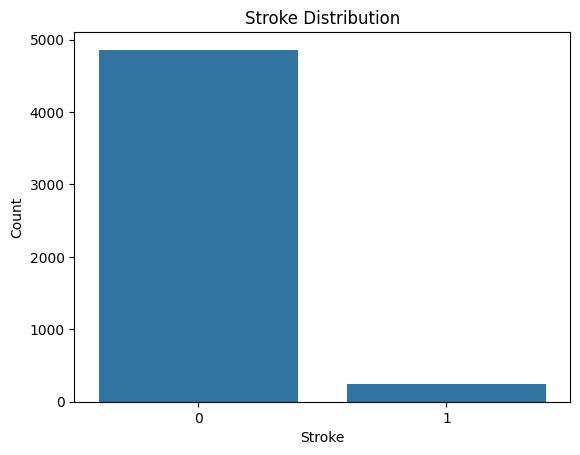

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='stroke', data=df)
plt.title('Stroke Distribution')
plt.xlabel('Stroke')
plt.ylabel('Count')
plt.show()

In [ ]:
df.drop(['group'],axis=1,inplace= True)
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.7,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
df.loc[
    (df['work_type'] == 'children') &
    (df['smoking_status'] == 'Unknown'),
    'smoking_status'
] = 'never smoked'

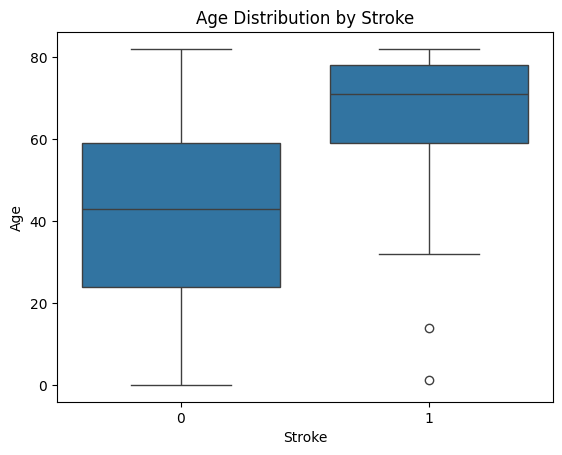

In [ ]:
sns.boxplot(x='stroke', y='age', data=df)
plt.title('Age Distribution by Stroke')
plt.xlabel('Stroke')
plt.ylabel('Age')
plt.show()

In [ ]:
df[(df['age']<20)&(df['stroke']==1)]

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
162,Female,1.32,0,0,No,children,Urban,70.37,18.9,never smoked,1
245,Female,14.00,0,0,No,children,Rural,57.93,30.9,never smoked,1


In [ ]:
df.drop([162, 245], inplace=True)

In [ ]:
df.reset_index(drop=True, inplace=True)

<module 'matplotlib.pyplot' from 'C:\\Users\\Right Click\\AppData\\Local\\Programs\\Python\\Python314\\Lib\\site-packages\\matplotlib\\pyplot.py'>

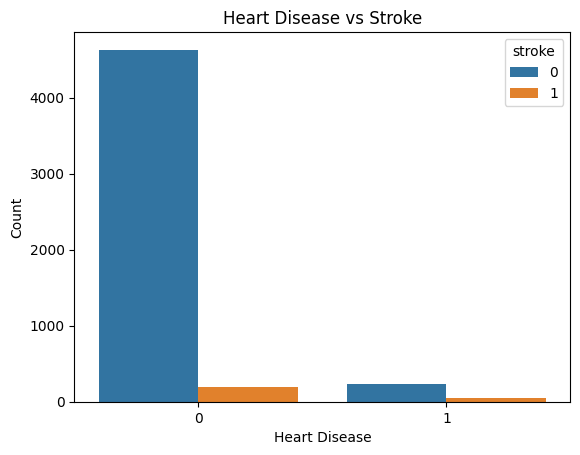

In [ ]:
sns.countplot(x='heart_disease', hue='stroke', data=df)
plt.title('Heart Disease vs Stroke')
plt.xlabel('Heart Disease')
plt.ylabel('Count')
plt

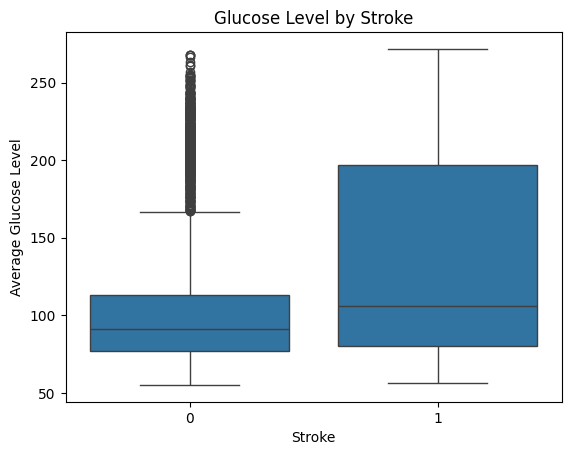

In [ ]:
sns.boxplot(x='stroke', y='avg_glucose_level', data=df)
plt.title('Glucose Level by Stroke')
plt.xlabel('Stroke')
plt.ylabel('Average Glucose Level')
plt.show()

In [ ]:
df[(df['avg_glucose_level']>160) & (df['stroke']==0)]

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
251,Male,14.0,0,0,No,Never_worked,Rural,161.28,19.1,Unknown,0
252,Female,47.0,0,0,Yes,Private,Urban,210.95,50.1,Unknown,0
254,Female,75.0,0,1,Yes,Self-employed,Rural,243.53,27.0,never smoked,0
256,Female,74.0,1,0,Yes,Self-employed,Urban,205.84,54.6,never smoked,0
259,Female,37.0,0,0,Yes,Private,Rural,162.96,39.4,never smoked,0
...,...,...,...,...,...,...,...,...,...,...,...
5060,Female,82.0,0,0,Yes,Self-employed,Rural,211.58,36.9,never smoked,0
5061,Male,39.0,0,0,Yes,Private,Urban,179.38,27.7,Unknown,0
5062,Male,70.0,0,0,Yes,Self-employed,Rural,193.88,24.3,Unknown,0
5074,Female,34.0,0,0,Yes,Private,Rural,174.37,23.0,never smoked,0


In [ ]:
df = df[~((df['avg_glucose_level']>140) & (df['stroke']==0))]

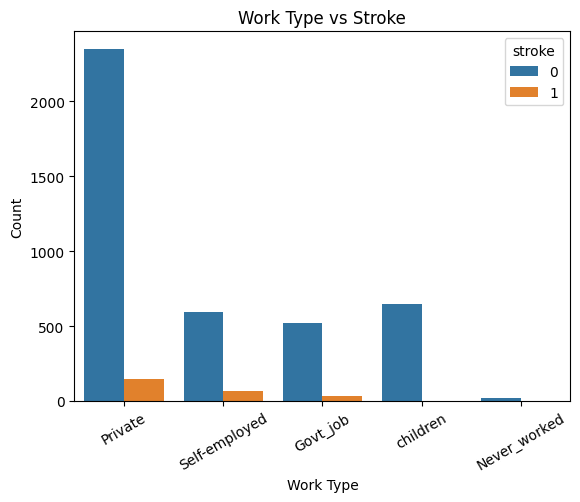

In [ ]:
sns.countplot(x='work_type', hue='stroke', data=df)
plt.title('Work Type vs Stroke')
plt.xlabel('Work Type')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.show()

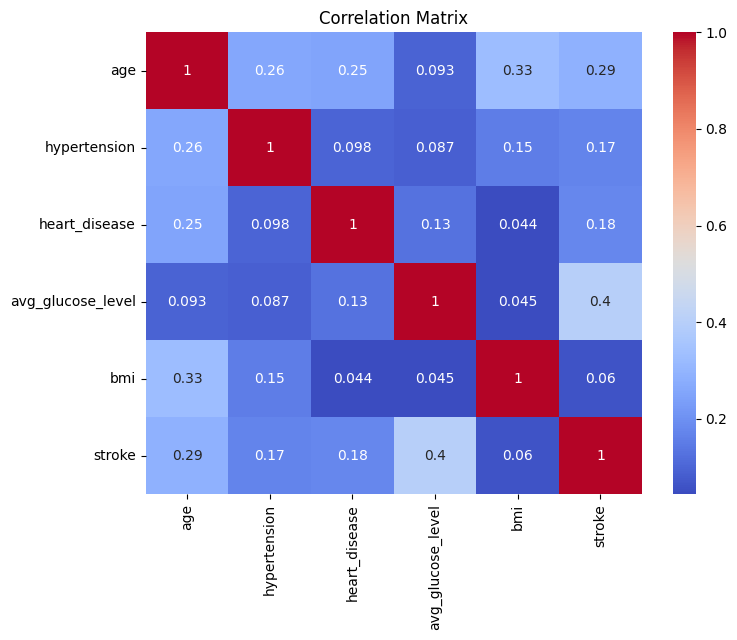

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Matrix')
plt.show()

In [ ]:
from sklearn.preprocessing import OneHotEncoder

categorical_cols = [
    'gender',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status'
]

onehot = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore'
)

encoded = onehot.fit_transform(df[categorical_cols])

In [ ]:
encoded_df = pd.DataFrame(
    encoded,
    columns=onehot.get_feature_names_out(categorical_cols),
    index=df.index
)

In [ ]:
encoded_df.head()

,gender_Female,gender_Male,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
df.drop(categorical_cols, axis=1, inplace=True)
df = pd.concat([df, encoded_df], axis=1)

In [ ]:
X = df.drop([ 'stroke'], axis=1)
y = df['stroke']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(y_train.mean(), y_test.mean())

0.05650684931506849 0.05593607305936073


In [ ]:

num_cols = ["age", "avg_glucose_level", "bmi"]
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method="yeo-johnson")   # includes standardization
X_train[num_cols] = pt.fit_transform(X_train[num_cols])
X_test[num_cols] = pt.transform(X_test[num_cols])

<Axes: title={'center': 'bmi'}>

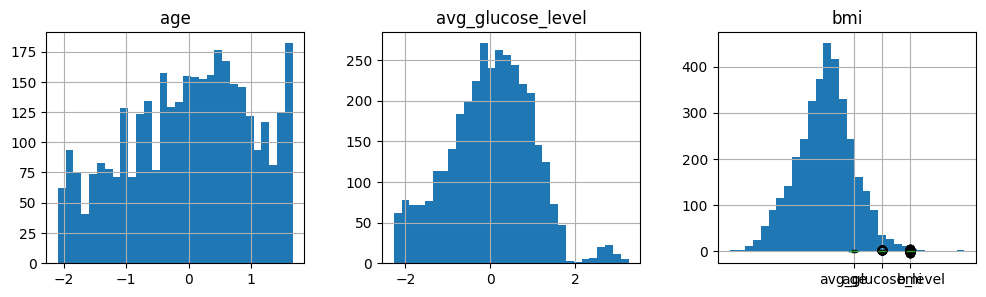

In [ ]:

X_train[num_cols].hist(bins=30, figsize=(12, 3), layout=(1, 3))
X_train[num_cols].boxplot(figsize=(8, 4))

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[827   0]
 [ 33  16]]


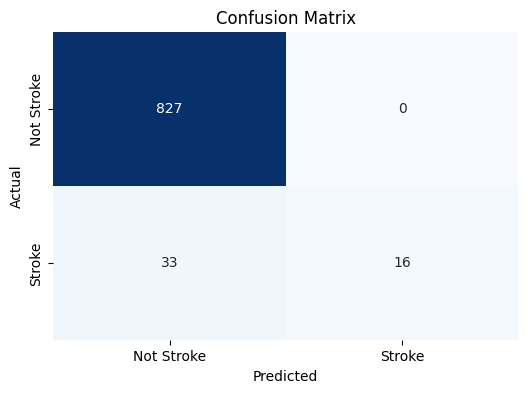


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      1.00      0.98       827
      Stroke       1.00      0.33      0.49        49

    accuracy                           0.96       876
   macro avg       0.98      0.66      0.74       876
weighted avg       0.96      0.96      0.95       876

ROC-AUC: 0.9112849492880586


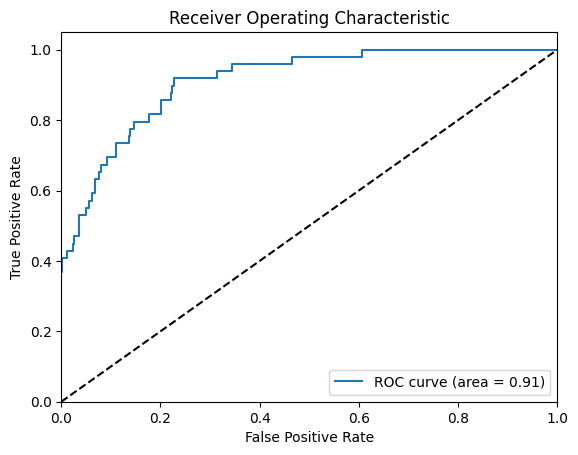

PR AUC: 0.5882677625964569


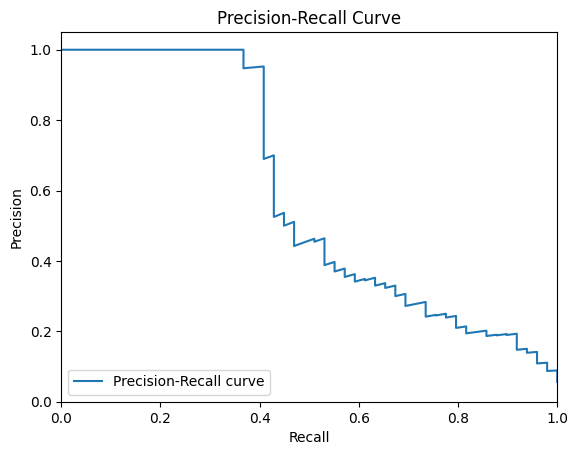

  8%|▊         | 1/13 [00:00<00:04,  2.69it/s]


Confusion Matrix:
 [[827   0]
 [ 32  17]]


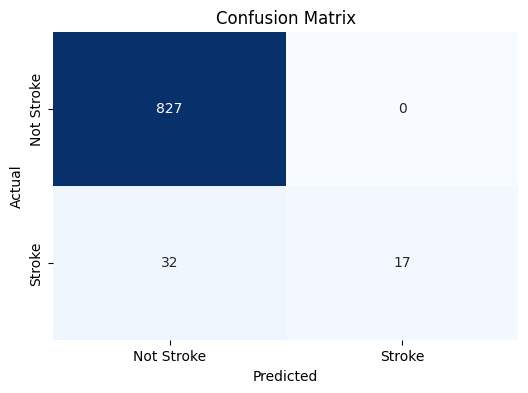


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      1.00      0.98       827
      Stroke       1.00      0.35      0.52        49

    accuracy                           0.96       876
   macro avg       0.98      0.67      0.75       876
weighted avg       0.96      0.96      0.95       876

ROC-AUC: 0.7712163462724873


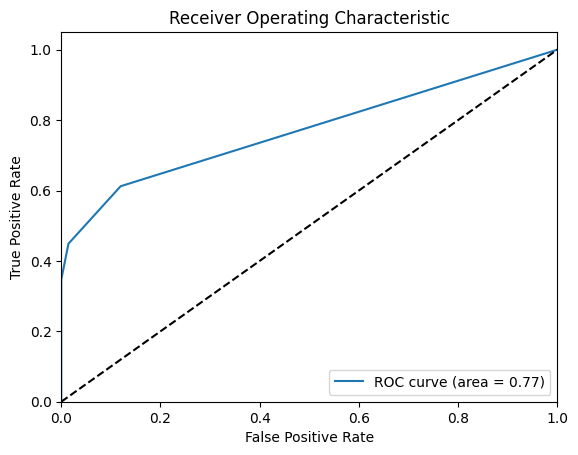

PR AUC: 0.4726233596337548


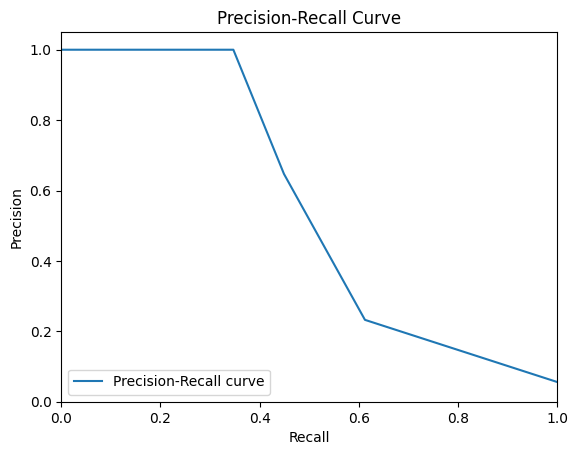

 15%|█▌        | 2/13 [00:01<00:06,  1.73it/s]C:\Users\Right Click\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Confusion Matrix:
 [[827   0]
 [ 32  17]]


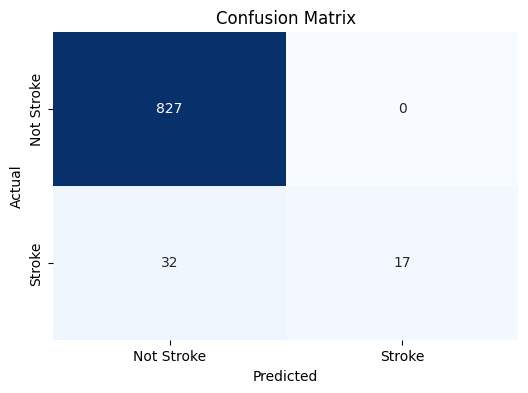


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      1.00      0.98       827
      Stroke       1.00      0.35      0.52        49

    accuracy                           0.96       876
   macro avg       0.98      0.67      0.75       876
weighted avg       0.96      0.96      0.95       876

ROC-AUC: 0.8249882782617278


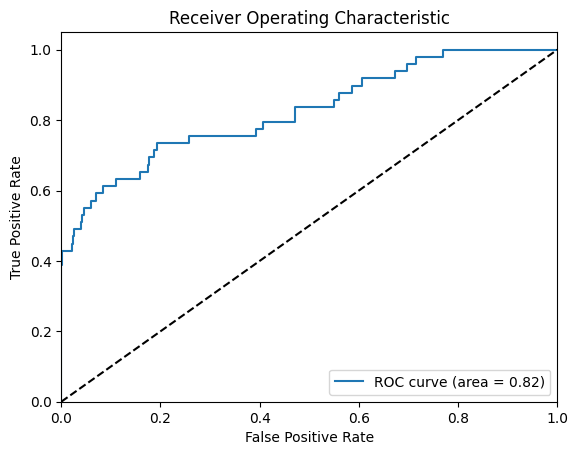

PR AUC: 0.5525522856781563


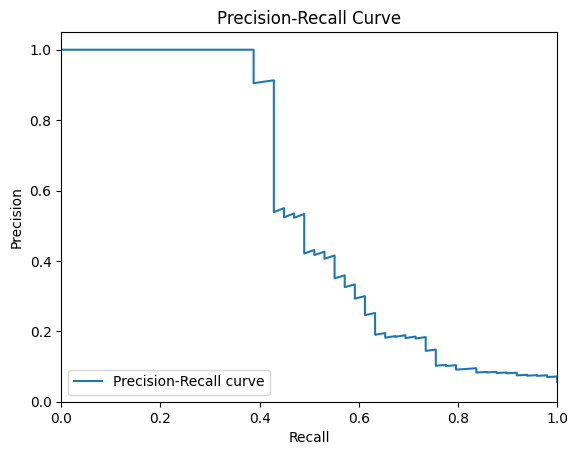

 23%|██▎       | 3/13 [00:02<00:08,  1.21it/s]


Confusion Matrix:
 [[801  26]
 [ 26  23]]


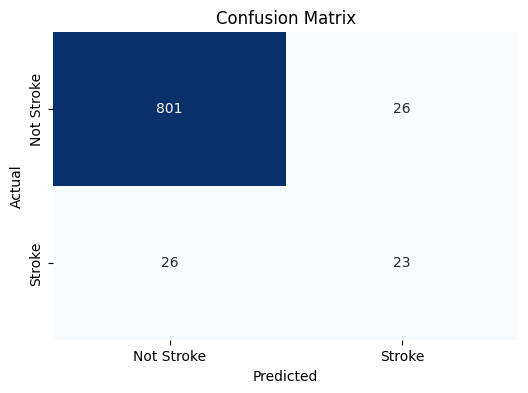


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.97      0.97      0.97       827
      Stroke       0.47      0.47      0.47        49

    accuracy                           0.94       876
   macro avg       0.72      0.72      0.72       876
weighted avg       0.94      0.94      0.94       876

ROC-AUC: 0.7189744095945513


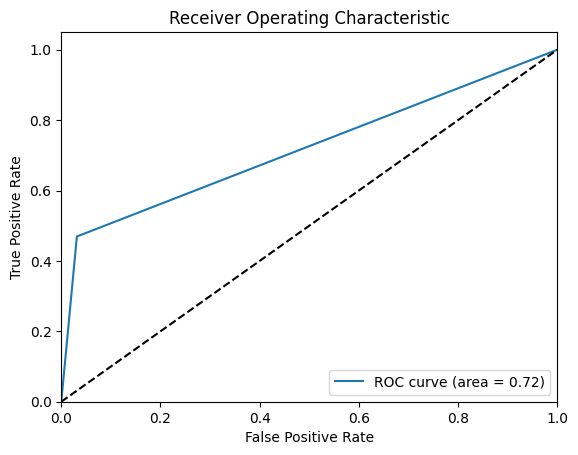

PR AUC: 0.2500052299365371


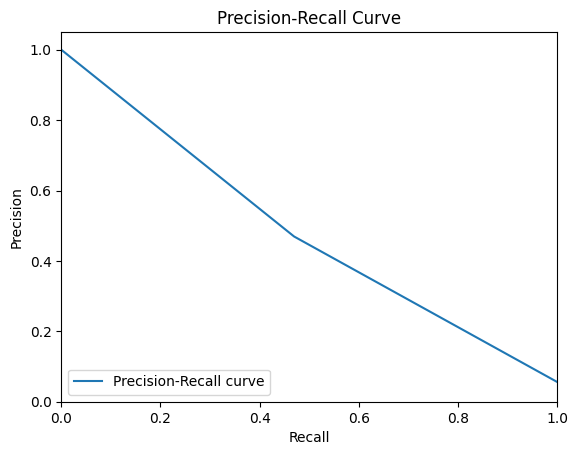

 31%|███       | 4/13 [00:02<00:05,  1.59it/s]


Confusion Matrix:
 [[268 559]
 [  0  49]]


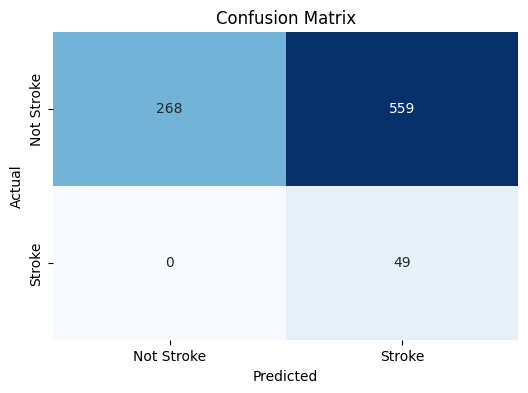


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.32      0.49       827
      Stroke       0.08      1.00      0.15        49

    accuracy                           0.36       876
   macro avg       0.54      0.66      0.32       876
weighted avg       0.95      0.36      0.47       876

ROC-AUC: 0.8826592305604225


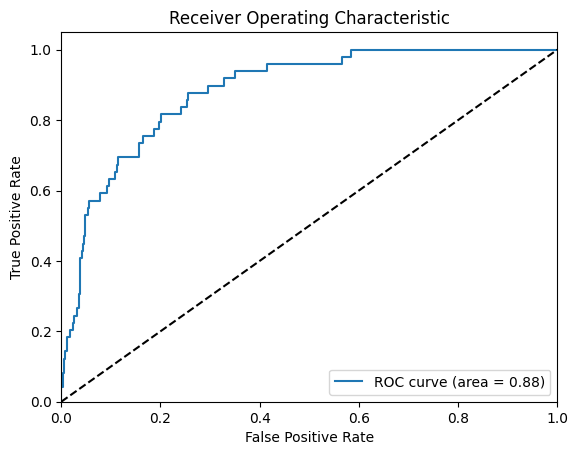

PR AUC: 0.3425387799423494


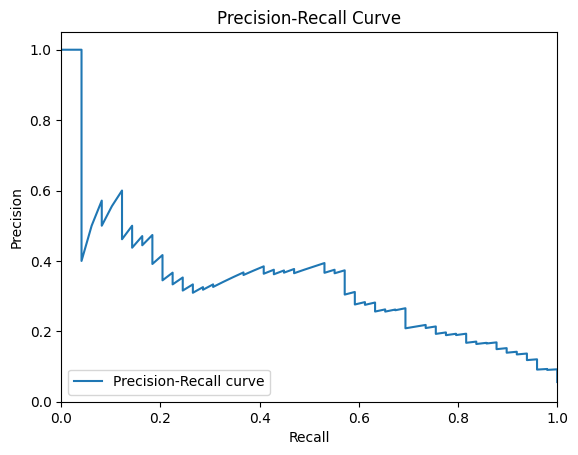

 38%|███▊      | 5/13 [00:02<00:04,  1.98it/s]


Confusion Matrix:
 [[825   2]
 [ 30  19]]


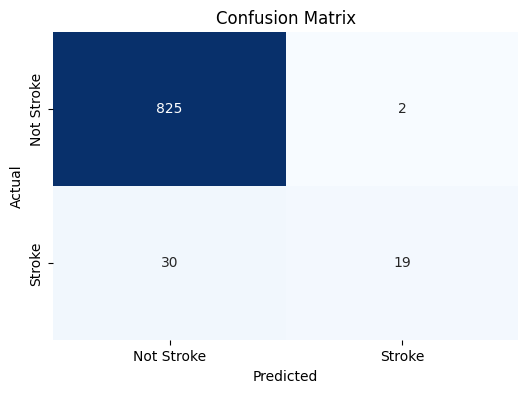


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      1.00      0.98       827
      Stroke       0.90      0.39      0.54        49

    accuracy                           0.96       876
   macro avg       0.93      0.69      0.76       876
weighted avg       0.96      0.96      0.96       876

ROC-AUC: 0.9095081805394467


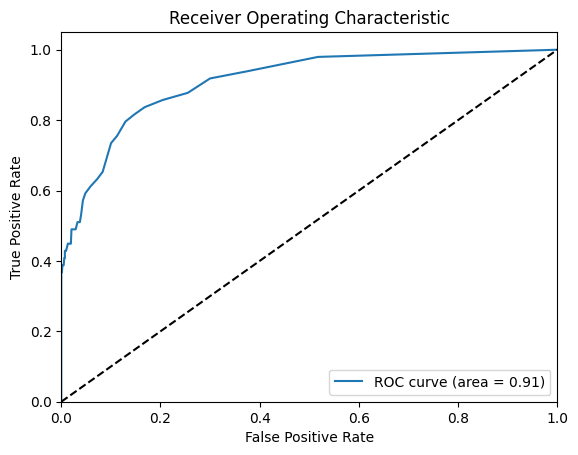

PR AUC: 0.5949598174686104


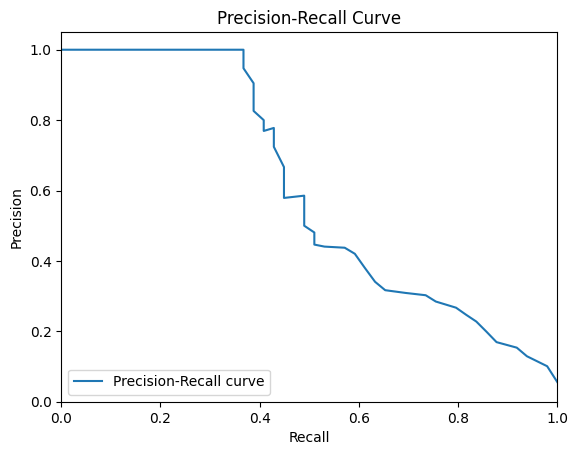

 46%|████▌     | 6/13 [00:03<00:03,  1.81it/s]


Confusion Matrix:
 [[825   2]
 [ 34  15]]


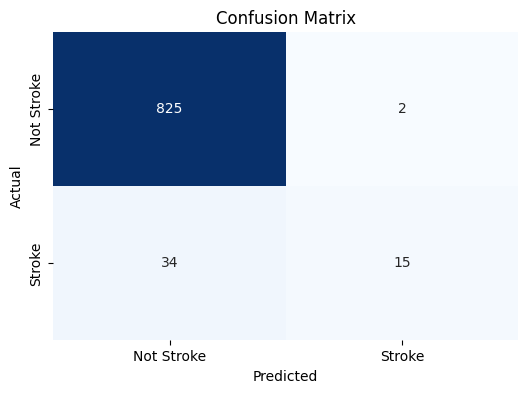


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      1.00      0.98       827
      Stroke       0.88      0.31      0.45        49

    accuracy                           0.96       876
   macro avg       0.92      0.65      0.72       876
weighted avg       0.96      0.96      0.95       876

ROC-AUC: 0.8771561829084717


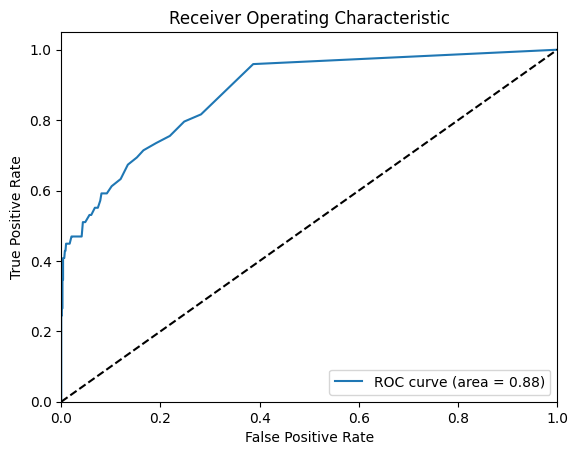

PR AUC: 0.5400405292752618


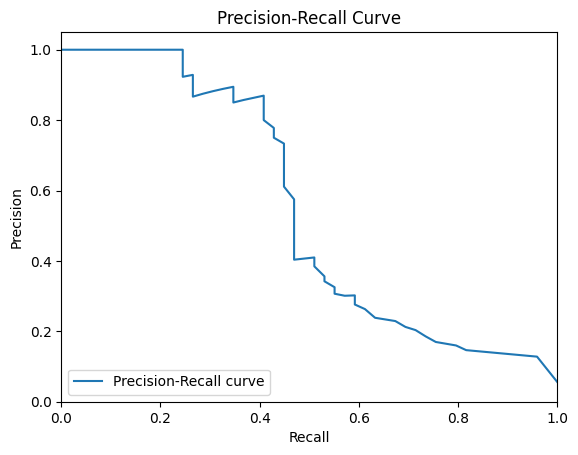

 54%|█████▍    | 7/13 [00:03<00:03,  1.97it/s]


Confusion Matrix:
 [[827   0]
 [ 31  18]]


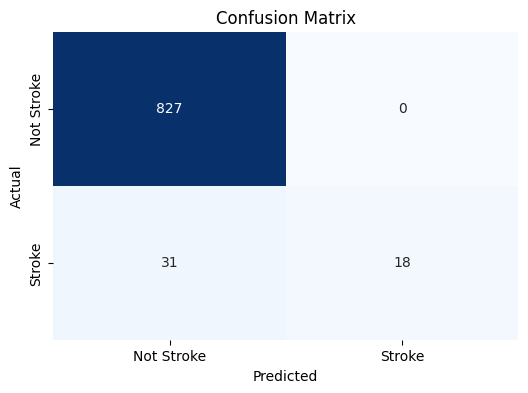


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      1.00      0.98       827
      Stroke       1.00      0.37      0.54        49

    accuracy                           0.96       876
   macro avg       0.98      0.68      0.76       876
weighted avg       0.97      0.96      0.96       876

ROC-AUC: 0.9246600695901093


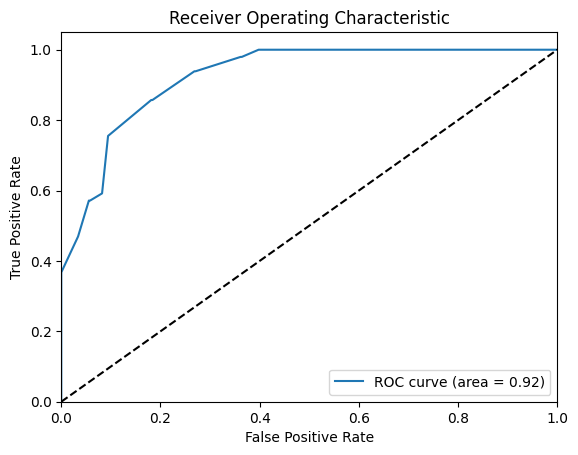

PR AUC: 0.5552302004621812


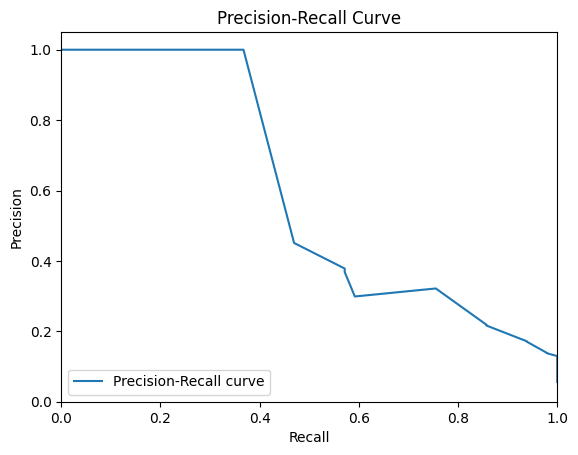

 62%|██████▏   | 8/13 [00:04<00:02,  2.23it/s]


Confusion Matrix:
 [[824   3]
 [ 31  18]]


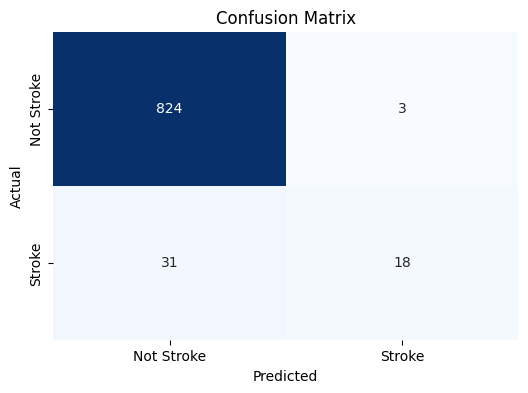


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      1.00      0.98       827
      Stroke       0.86      0.37      0.51        49

    accuracy                           0.96       876
   macro avg       0.91      0.68      0.75       876
weighted avg       0.96      0.96      0.95       876

ROC-AUC: 0.9337166547392839


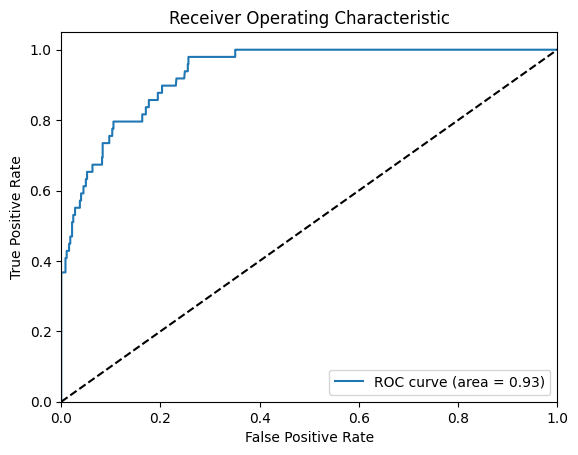

PR AUC: 0.6168506455629587


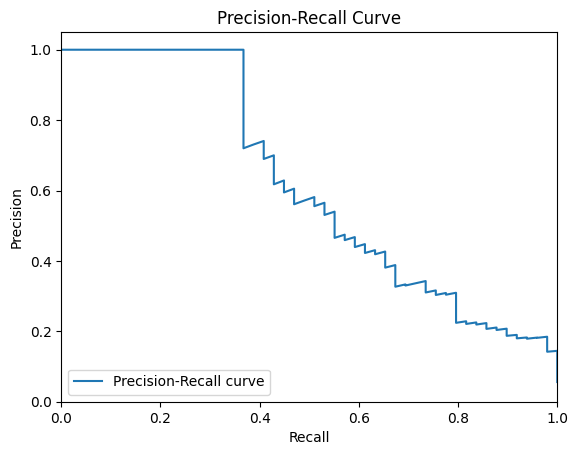

 69%|██████▉   | 9/13 [00:04<00:01,  2.19it/s]


Confusion Matrix:
 [[824   3]
 [ 30  19]]


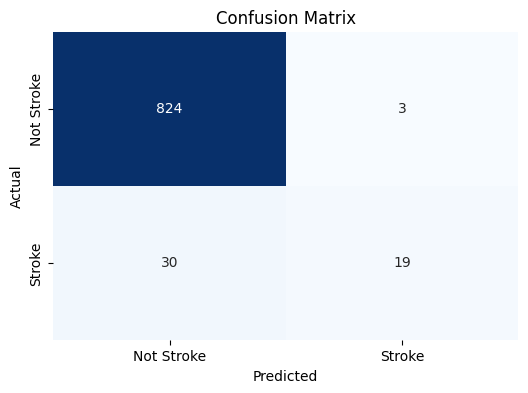


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      1.00      0.98       827
      Stroke       0.86      0.39      0.54        49

    accuracy                           0.96       876
   macro avg       0.91      0.69      0.76       876
weighted avg       0.96      0.96      0.96       876

ROC-AUC: 0.9137280063174


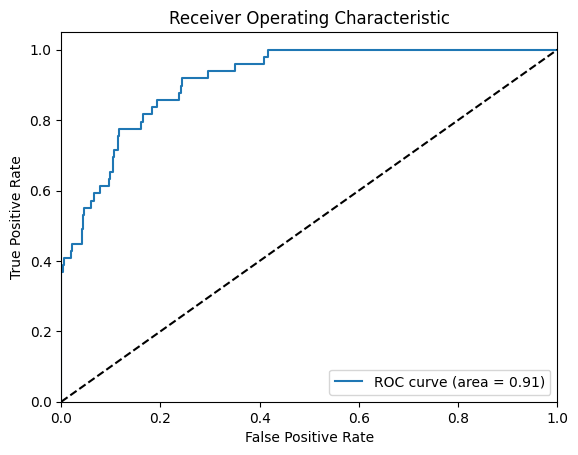

PR AUC: 0.5732658027006019


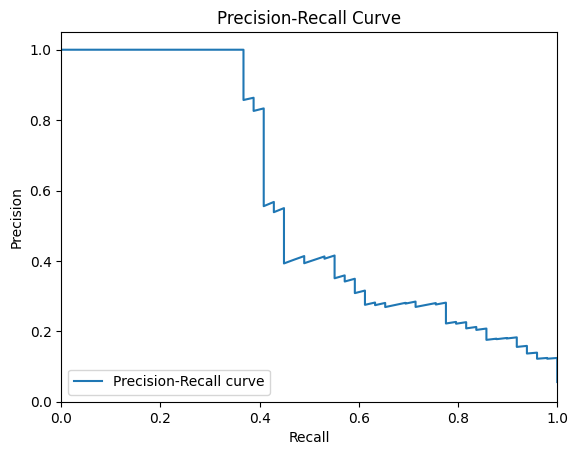

 77%|███████▋  | 10/13 [00:05<00:01,  2.16it/s]


Confusion Matrix:
 [[820   7]
 [ 30  19]]


C:\Users\Right Click\AppData\Local\Programs\Python\Python314\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:22:12] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


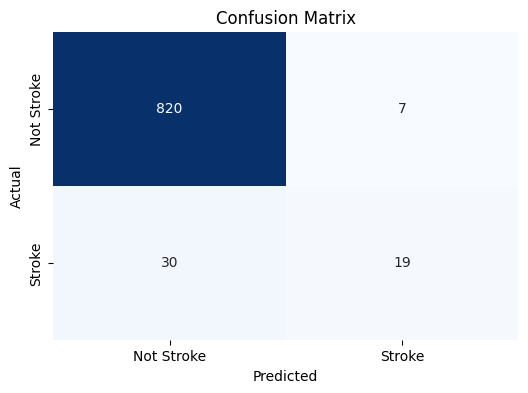


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.99      0.98       827
      Stroke       0.73      0.39      0.51        49

    accuracy                           0.96       876
   macro avg       0.85      0.69      0.74       876
weighted avg       0.95      0.96      0.95       876

ROC-AUC: 0.9072625422599512


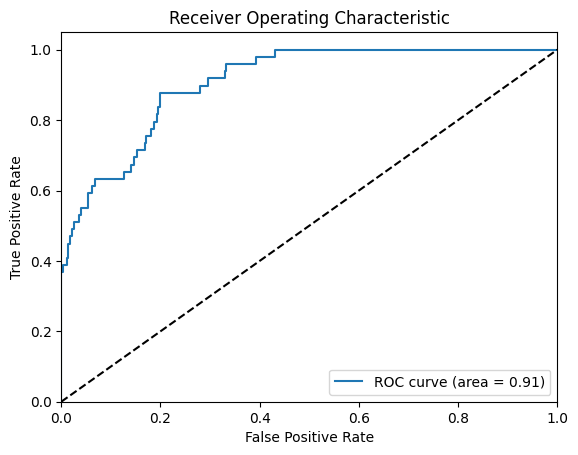

PR AUC: 0.5787852948394403


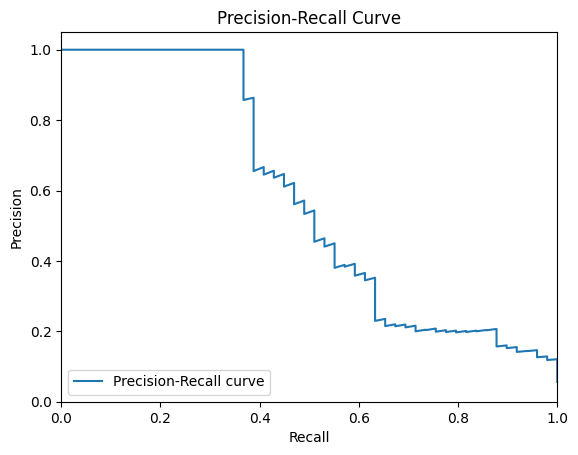

 85%|████████▍ | 11/13 [00:05<00:00,  2.23it/s]


Confusion Matrix:
 [[825   2]
 [ 30  19]]


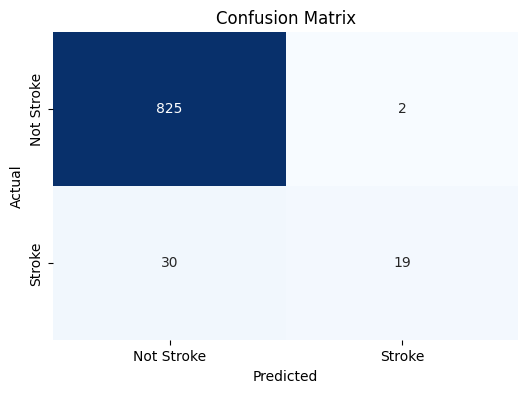


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      1.00      0.98       827
      Stroke       0.90      0.39      0.54        49

    accuracy                           0.96       876
   macro avg       0.93      0.69      0.76       876
weighted avg       0.96      0.96      0.96       876

ROC-AUC: 0.9190089578757743


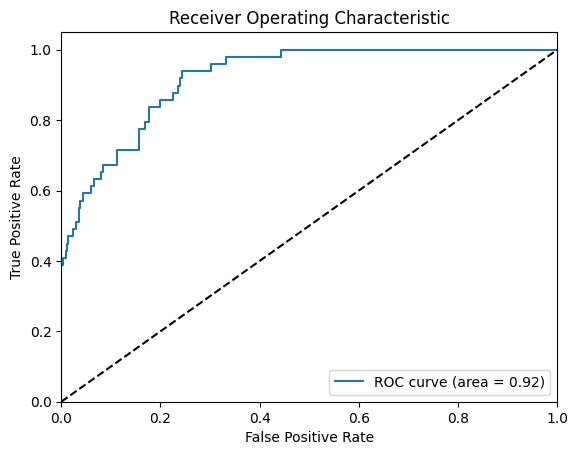

PR AUC: 0.6023301351177246


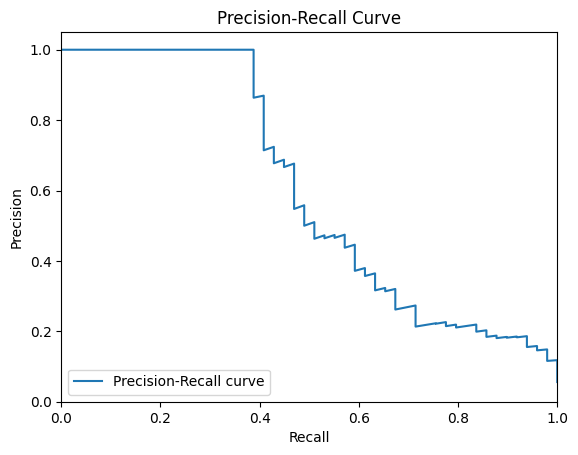

 92%|█████████▏| 12/13 [00:08<00:01,  1.16s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 198, number of negative: 3306
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000148 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 642
[LightGBM] [Info] Number of data points in the train set: 3504, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.056507 -> initscore=-2.815227
[LightGBM] [Info] Start training from score -2.815227

Confusion Matrix:
 [[825   2]
 [ 31  18]]


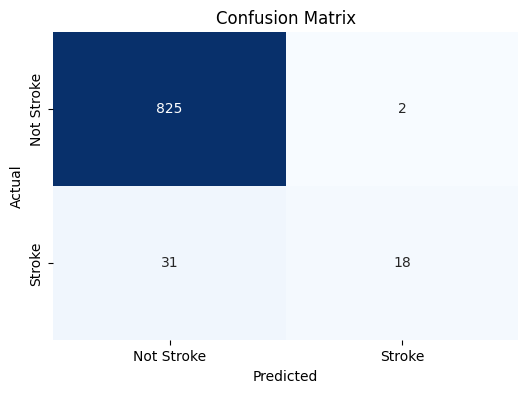


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      1.00      0.98       827
      Stroke       0.90      0.37      0.52        49

    accuracy                           0.96       876
   macro avg       0.93      0.68      0.75       876
weighted avg       0.96      0.96      0.95       876

ROC-AUC: 0.9127655899119018


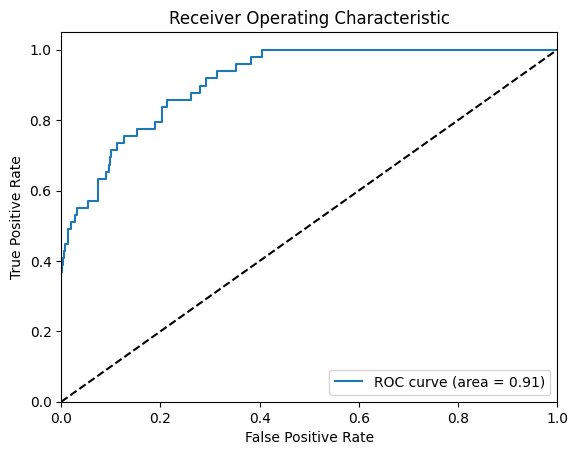

PR AUC: 0.6016856168542165


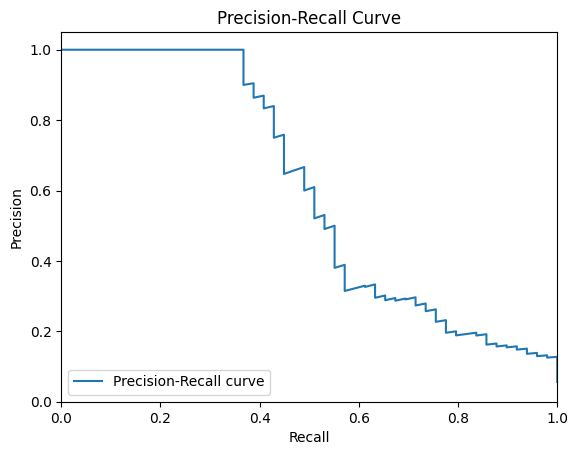

100%|██████████| 13/13 [00:08<00:00,  1.46it/s]


In [ ]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }


C:\Users\Right Click\AppData\Local\Programs\Python\Python314\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:22:52] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[823   4]
 [ 29  20]]


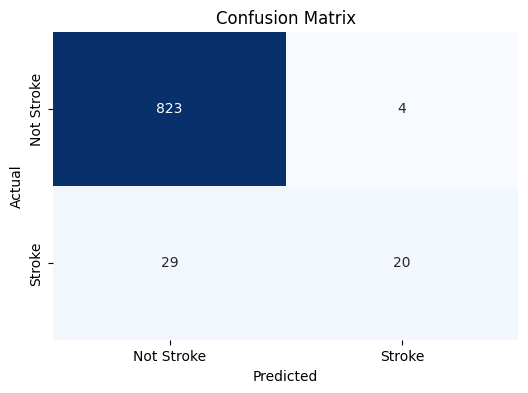


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.97      1.00      0.98       827
      Stroke       0.83      0.41      0.55        49

    accuracy                           0.96       876
   macro avg       0.90      0.70      0.76       876
weighted avg       0.96      0.96      0.96       876

ROC-AUC: 0.9293734422426769


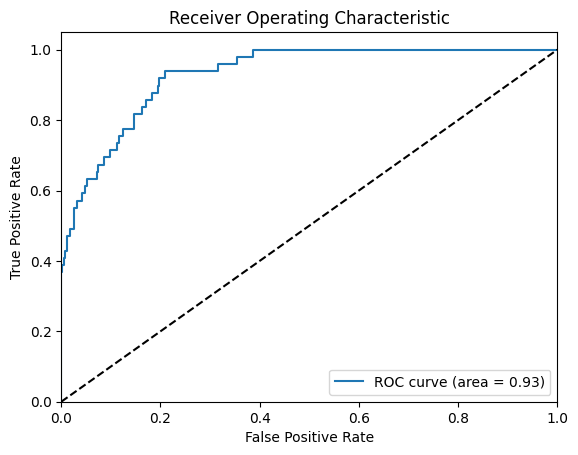

PR AUC: 0.620637108617527


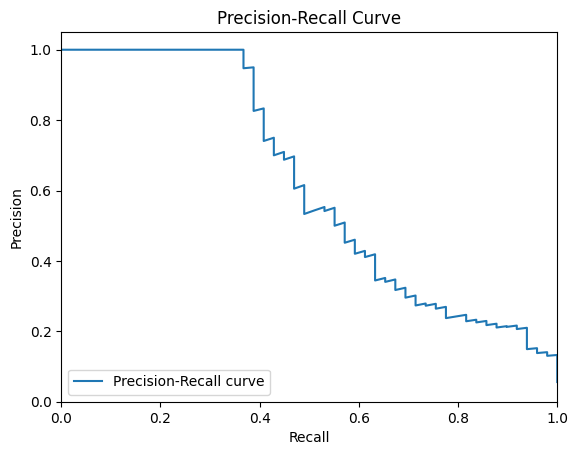

In [ ]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

C:\Users\Right Click\AppData\Local\Programs\Python\Python314\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:23:20] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[820   7]
 [ 29  20]]


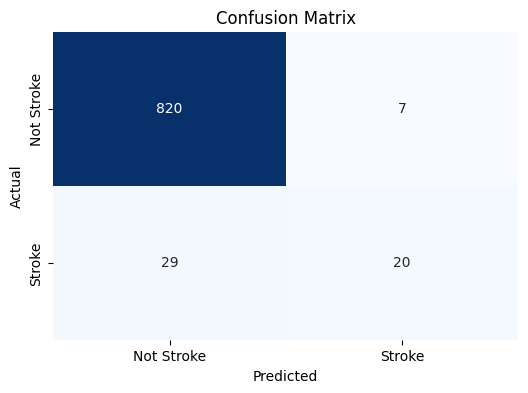


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.97      0.99      0.98       827
      Stroke       0.74      0.41      0.53        49

    accuracy                           0.96       876
   macro avg       0.85      0.70      0.75       876
weighted avg       0.95      0.96      0.95       876

ROC-AUC: 0.8711102336944452


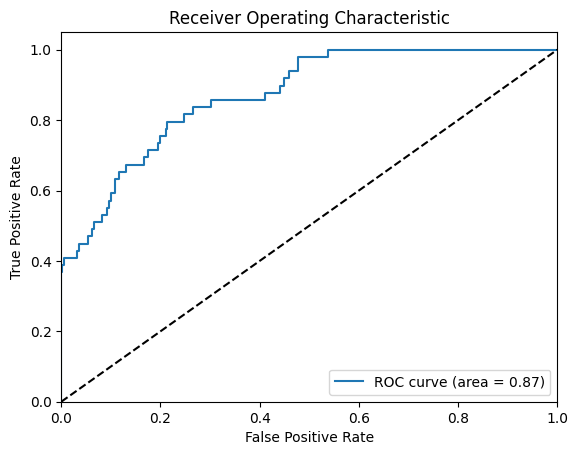

PR AUC: 0.5303826950734623


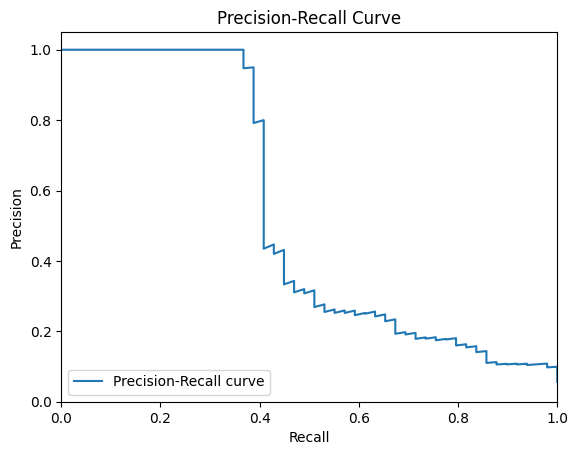

In [ ]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [ ]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Voting Classifier,1.000000,0.962329,1.000000,0.833333,1.000000,0.408163,1.000000,0.547945,1.000000,0.701663,0.929373,0.620637
CatBoost,0.983447,0.963470,1.000000,0.904762,0.707071,0.387755,0.828402,0.542857,0.853535,0.692668,0.919009,0.602330
Random Forest,1.000000,0.963470,1.000000,0.904762,1.000000,0.387755,1.000000,0.542857,1.000000,0.692668,0.909508,0.594960
AdaBoost,0.964897,0.964612,1.000000,1.000000,0.378788,0.367347,0.549451,0.537313,0.689394,0.683673,0.924660,0.555230
Hist Gradient Boosting,0.998573,0.962329,1.000000,0.863636,0.974747,0.387755,0.987212,0.535211,0.987374,0.692064,0.913728,0.573266
Stacking Classifier,0.995719,0.958904,0.937799,0.740741,0.989899,0.408163,0.963145,0.526316,0.992983,0.699849,0.871110,0.530383
LightGBM,0.999429,0.962329,1.000000,0.900000,0.989899,0.367347,0.994924,0.521739,0.994949,0.682464,0.912766,0.601686
KNN,0.960902,0.963470,0.955224,1.000000,0.323232,0.346939,0.483019,0.515152,0.661162,0.673469,0.771216,0.472623
SVC,0.963470,0.963470,1.000000,1.000000,0.353535,0.346939,0.522388,0.515152,0.676768,0.673469,0.824988,0.552552
Gradient Boosting,0.969178,0.961187,1.000000,0.857143,0.454545,0.367347,0.625000,0.514286,0.727273,0.681860,0.933717,0.616851


<Axes: >

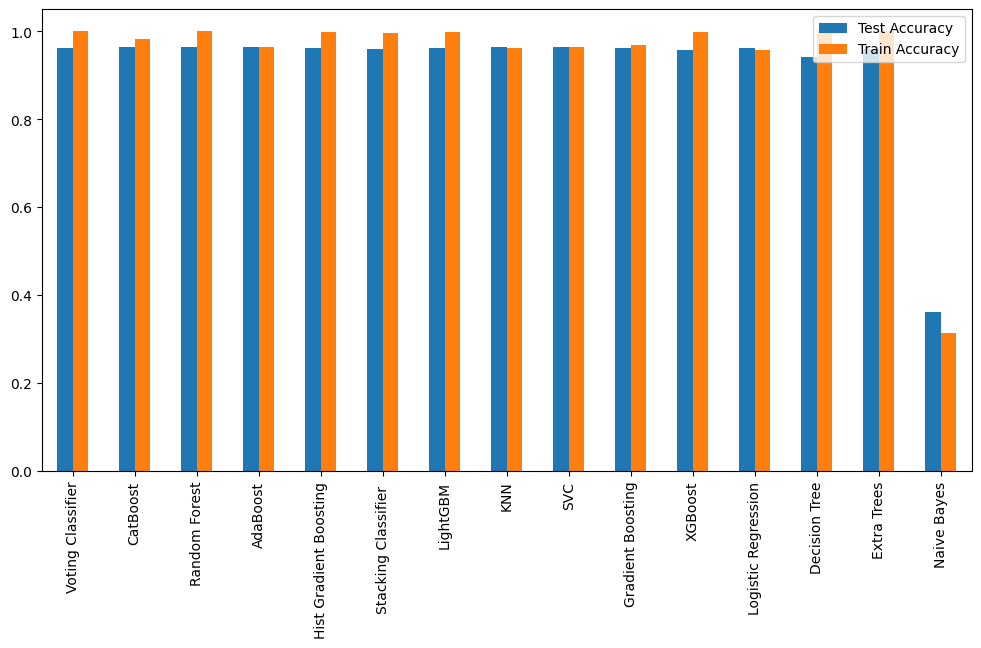

In [ ]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

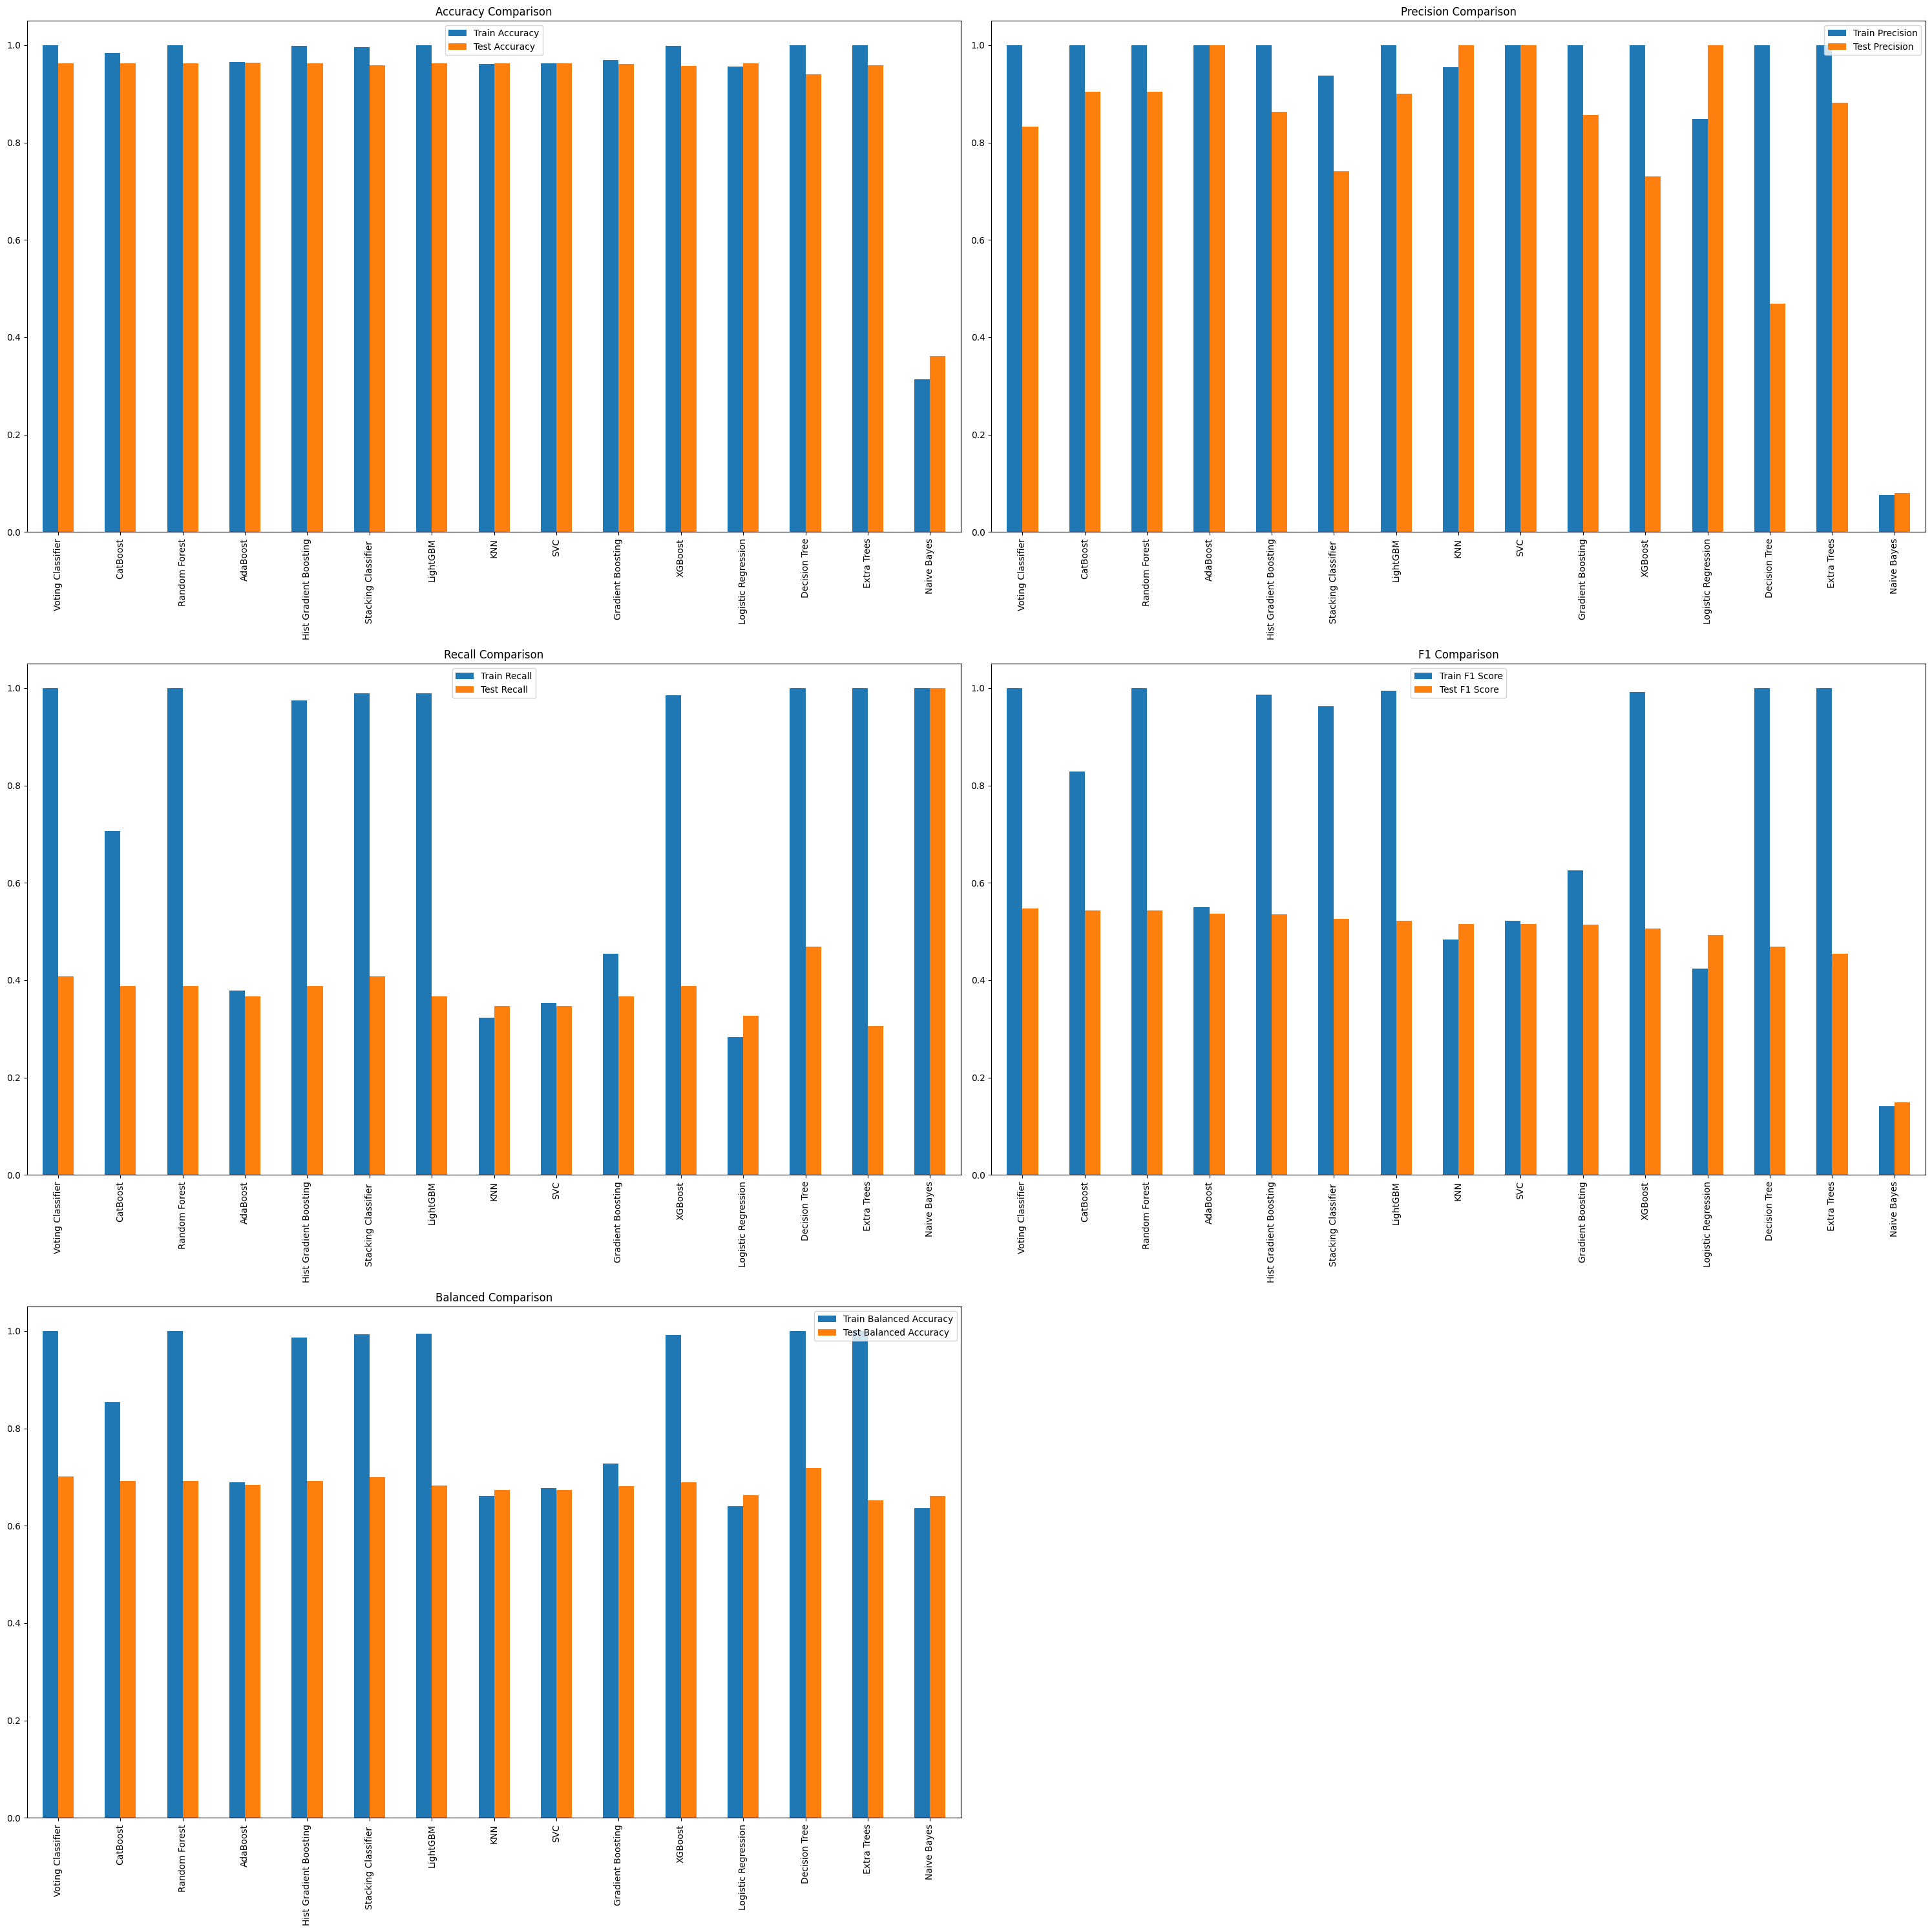

In [ ]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()